# Datasets & data candidates
**Video-based environment memory with an affordance feature layer** · group meeting, 9 Nov 2026

- **Primary dataset: SceneFun3D.** One scene is on the Mac (0.9 GB) and passes all E0 alignment checks.
- **Pipeline mechanics work end to end on the Mac:** features → 3D memory → query (Lab 1).
- **Complement: EPIC-KITCHENS + VISOR.** One real kitchen video with hand–object contacts, narrations and camera poses (125 MB).

In [1]:
import contextlib
import io
import json
import os
import sys
from pathlib import Path

import imageio.v3 as iio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.scenefun3d import index_sequence, read_annotations, read_laser_scan, upright_cw_turns
from affordance3d.viz import subsample
from report.epic_helpers import (AlignedScene, contact_examples_figure, epic_3d_figure, overview_table,
                                 read_epic_fields, read_narrations, read_visor, render_visor_walkthrough)
from report.report_helpers import (camera_path, capability_table, label_colours, pick_task_examples, read_descriptions,
                                   render_walkthrough, scene_3d_figure, show_row, split_counts,
                                   task_examples_figure)

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
RUNS, ASSETS = ROOT / "runs", ROOT / "report" / "assets"
DATA, VISIT, VIDEO = ROOT / "data" / "scenefun3d", "421069", "42444490"
MIN_VISIBLE = 10  # annotated points passing the depth test for a part to count as "seen" (as in E0)

## 1 · Candidate landscape
> **This section:** what each candidate dataset or simulator provides, and what its data looks like.  
> **Most promising:** SceneFun3D is the only one with video, poses, functional parts *and* task language together. EPIC/VISOR and HOI4D add what it lacks: observed interaction and state change.

✓ provided · ~ partial / derived / proxy · – not provided. Condensed from the survey sheets in `docs/outputs/pipeline_v3_research_202611/` (official pages reviewed 2–5 Nov). **Only SceneFun3D has been checked against downloaded data.**

In [2]:
capability_table()

,type,Continuous video,Depth + poses,3D geometry,Functional-part labels,Language,Observed interaction,State change,Robot actions,role in plan,local
SceneFun3D,real,✓,✓,✓,✓,✓,–,–,–,E0 ✓ · E1 · E2 (12 scenes),1 scene local · E0 pass
EPIC-KITCHENS + VISOR (+2HANDS),real,✓,~,~,~,✓,✓,~,–,real-video history retrieval,1 video local (P28_101)
HOI4D,real,✓,✓,✓,–,–,✓,✓,–,interaction phases + geometry,survey
3RScan,real,✓,✓,✓,–,–,–,✓,–,real rescans: change / stale memory,survey
Aria Digital Twin,real,✓,✓,✓,–,–,~,✓,–,"dynamic objects, revisits",survey
UMD Part Affordance,real,–,~,–,✓,–,–,–,–,backup: local affordance head,survey
ContactPose,real,–,✓,✓,~,–,✓,–,–,aux: observed-contact check,survey
ManiSkill / SAPIEN,sim,✓,✓,✓,~,–,✓,✓,✓,E3: controlled occupancy / state,survey
AI2-THOR,sim,✓,✓,✓,~,–,~,✓,~,"E3 alt.: room revisits, object states",survey


### What each candidate looks like (official project images, in table order)

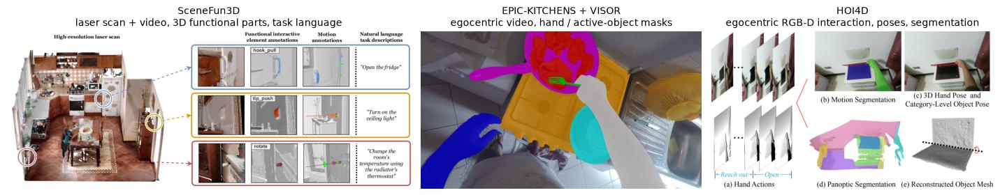

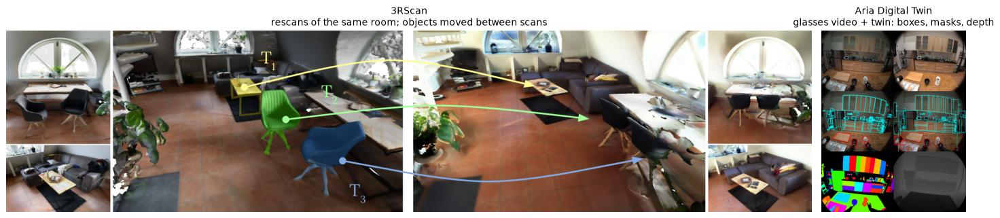

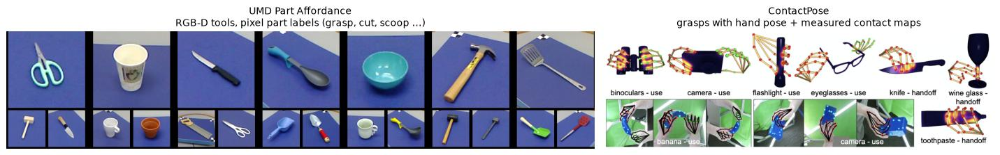

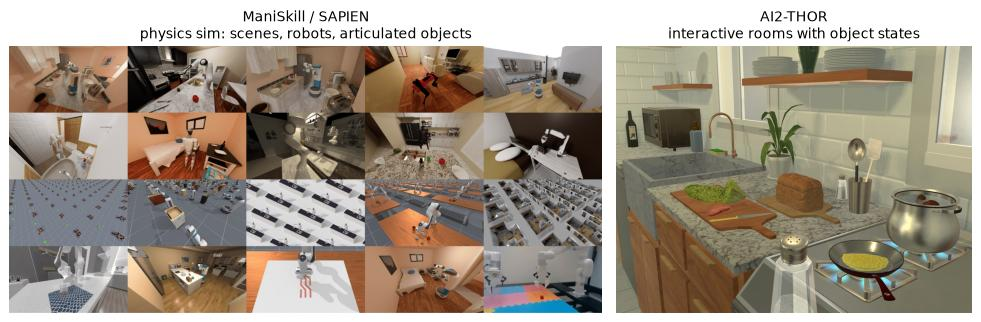

In [3]:
EXT = ASSETS / "external"  # official project images, not our results
for row, width in [
    ([(EXT / "scenefun3d.png", "SceneFun3D\nlaser scan + video, 3D functional parts, task language"),
      (EXT / "epic_visor.png", "EPIC-KITCHENS + VISOR\negocentric video, hand / active-object masks"),
      (EXT / "hoi4d.png", "HOI4D\negocentric RGB-D interaction, poses, segmentation")], 16),
    ([(EXT / "rio_3rscan.png", "3RScan\nrescans of the same room; objects moved between scans"),
      (EXT / "adt.jpg", "Aria Digital Twin\nglasses video + twin: boxes, masks, depth")], 16),
    ([(EXT / "umd.png", "UMD Part Affordance\nRGB-D tools, pixel part labels (grasp, cut, scoop …)"),
      (EXT / "contactpose.png", "ContactPose\ngrasps with hand pose + measured contact maps")], 16),
    ([(EXT / "maniskill.jpg", "ManiSkill / SAPIEN\nphysics sim: scenes, robots, articulated objects"),
      (EXT / "ai2thor.jpg", "AI2-THOR\ninteractive rooms with object states")], 11),
]:
    show_row(row, width=width, fontsize=11)
plt.show()

<sub>Sources: scenefun3d.github.io · epic-kitchens.github.io/VISOR · hoi4d.github.io · waldjohannau.github.io/RIO · projectaria.com/datasets/adt · users.umiacs.umd.edu/~fermulcm/affordance · github.com/facebookresearch/ContactPose · github.com/mani-skill/ManiSkill · github.com/allenai/ai2thor</sub>

**Later, for the VLA route (not first round):** H2RBench · HumanGen + RoboTwin · RH20T · LIBERO

## 2 · Where each dataset enters the plan
> **This section:** which data each experiment stage uses, and where it runs.  
> **Most promising:** SceneFun3D alone carries E0 → E2, so one loader and one download script cover everything until E3.

```text
E0  data + projection check         SceneFun3D, 1 scene                       Mac        ✅ done
E1  frozen features, memory readout SceneFun3D, dev scene + 1 check scene     Mac        ▶ next
E2  affordance layer vs controls    SceneFun3D, 12 scenes (8 / 2 / 2)         Isambard
E3  environment / state change      ManiSkill (alt. AI2-THOR, 3RScan)         later
 +  memory over real video          EPIC-KITCHENS + VISOR  or  HOI4D          later
backup: local affordance head       UMD Part Affordance
```

## 3 · Lab 1 · pipeline mechanics on a small RGB-D sample
> **This section:** the full memory loop on 5 frames: features → 3D memory with source frames → query → visible / out of view / occluded.  
> **Most promising:** the voxel memory with per-frame provenance and the coverage split are the skeleton E1 reuses directly. DINOv2 takes about 60 ms per frame on the Mac, so features are not the bottleneck.

Open3D Redwood sample: a synthetic living room, 5 RGB-D frames, odometry poses (not SceneFun3D) · `notebooks/01_step_by_step_demo.ipynb`
```text
RGB-D frame ─► DINOv2 ViT-S/14 patch features ─► back-project with depth + pose
            ─► 3 cm voxel memory (feature + which frames saw it)
            ─► query one patch: cosine match ─► visible now / out of view / occluded
```

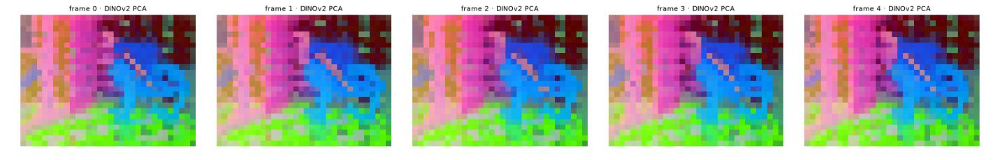

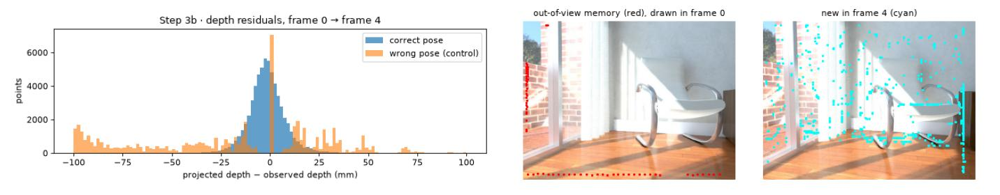

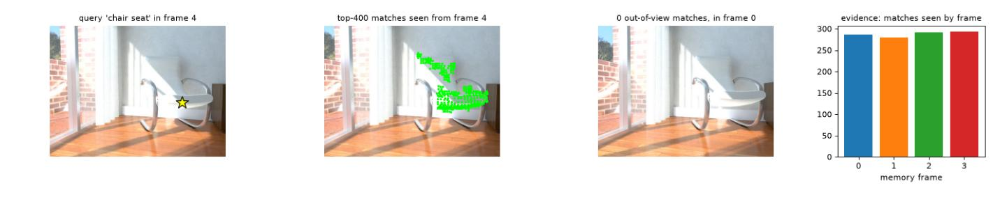

,value
"depth residual, frame 0 → 4 (median)",5.6 mm
same with a wrong pose (control),40.0 mm
"DINOv2 on Apple MPS, after warm-up",60 ms / frame
memory from 4 frames,"8,593 voxels, 13.0 MB"


In [4]:
R = RUNS / "demo_redwood"
show_row([(R / "step4_features.png", "")], width=16)
show_row([(R / "step3b_residuals.png", ""), (R / "step6_coverage.png", "")], width=16)
show_row([(R / "step7_query_chair_seat.png", "")], width=16)
plt.show()

m = json.loads((R / "metrics.json").read_text())
residuals, memory = m["e0_depth_residuals"], m["memory"]
pd.DataFrame({"value": {
    "depth residual, frame 0 → 4 (median)": f"{residuals['0 → 4']['median |Δz| (mm)']} mm",
    "same with a wrong pose (control)": f"{residuals['0 → 4 WRONG pose (control)']['median |Δz| (mm)']} mm",
    "DINOv2 on Apple MPS, after warm-up": f"{np.median(m['features_ms_per_frame'][1:]):.0f} ms / frame",
    "memory from 4 frames": f"{memory['voxels (3 cm)']:,} voxels, {memory['memory size (MB)']} MB",
}})

## 4 · SceneFun3D: the primary dataset
> **This section:** the scene we use: splits, the video, the 3D scan and the task language.  
> **Most promising:** task → part links give query/answer pairs for E1–E2 without extra labelling. The camera passes each part and moves on, which gives natural "seen earlier, out of view now" queries for memory readout.

Real indoor scenes: a Faro laser scan (5 mm), iPad RGB video with rendered depth and poses, 3D functional parts of 9 types, and language tasks. License: CC-BY-4.0 plus the ARKitScenes terms.

In [5]:
split_counts(ROOT / "third_party" / "scenefun3d" / "benchmark_file_lists").T

,train,val,test
scenes (visits),200,30,85
videos,527,82,220


In [6]:
SCENE = DATA / VISIT
scan_xyz, scan_rgb = read_laser_scan(SCENE / f"{VISIT}_laser_scan.ply")
crop = np.load(SCENE / f"{VISIT}_crop_mask.npy").astype(bool)
elements = read_annotations(SCENE / f"{VISIT}_annotations.json")
index = index_sequence(DATA, VISIT, VIDEO)
TURNS = upright_cw_turns(list(index.poses.values()))  # hires frames are already upright: 0 turns

heights, edges = np.histogram(scan_xyz[crop, 2], bins=200)
floor_z = edges[np.argmax(heights)]  # densest horizontal slab = floor
below_ceiling = np.flatnonzero(crop & (scan_xyz[:, 2] < floor_z + 1.6))  # display only: hide the ceiling
display_idx = below_ceiling[subsample(len(below_ceiling), 200_000)]
times = index.depth_times[::4]
print(f"{len(scan_xyz):,} scan points · {len(elements)} functional parts · {len(index.depth_times)} frames, "
      f"{float(index.depth_times[-1]) - float(index.depth_times[0]):.0f} s · rotation from poses: {TURNS} turns")

8,880,684 scan points · 38 functional parts · 1025 frames, 113 s · rotation from poses: 0 turns


### Walkthrough of video 42444490 with ORACLE functional parts (every 4th frame)

In [7]:
VIDEO_PATH = ASSETS / "walkthrough_421069.mp4"
log = render_walkthrough(index, times, TURNS, pixel_step=4, elements=elements, scan_xyz=scan_xyz,
                         display_xy=scan_xyz[display_idx, :2], out_path=VIDEO_PATH, fps=12)
seen = (log.visible_points >= MIN_VISIBLE).any(axis=0)
duration = float(times[-1]) - float(times[0])
print(f"{len(times)} frames shown at {duration / (len(times) / 12):.1f}× real time · "
      f"{seen.sum()}/{len(elements)} functional parts seen at least once")
Video(str(VIDEO_PATH), embed=True, width=1100)

257 frames shown at 5.3× real time · 36/38 functional parts seen at least once


### 3D: laser scan, functional parts, camera path (drag to rotate; click the legend to toggle)

In [8]:
centres, _ = camera_path(index, index.rgb_times)
scene_3d_figure(scan_xyz[display_idx], scan_rgb[display_idx], elements, scan_xyz, label_colours(elements), centres)

### Language task → functional part

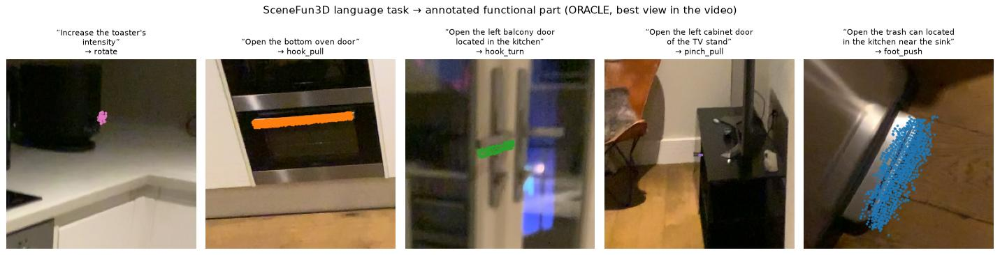

In [9]:
examples = pick_task_examples(read_descriptions(SCENE / f"{VISIT}_descriptions.json"), elements, seen, n=5)
task_examples_figure(examples, elements, log, index, TURNS, scan_xyz)
plt.show()

## 5 · Lab 2 · E0 alignment checks (20 frames, 720×960)
> **This section:** verifies that RGB, depth, intrinsics, poses and the 3D labels line up.  
> **Most promising:** projection is accurate to about 2 px at 720×960, so 3D part labels can be turned into per-frame 2D masks automatically. That gives training supervision and evaluation for E1–E2 without manual labelling, and the same checks rerun on every new scene.

Do RGB, depth, intrinsics, poses and annotations line up? · `notebooks/02_scenefun3d_e0.ipynb`

In [10]:
E0 = RUNS / "scenefun3d_e0"
manifest = json.loads((E0 / "manifest.json").read_text())
r, gate = manifest["results"], manifest["config"]["thresholds"]
checks = pd.DataFrame([
    {"check": "image orientation (from poses)", "measured": "0 turns, all frames within 30° of upright",
     "gate": f"< {gate['upright_max_abs_angle_deg']:.0f}°", "control": "metadata 'Left' would be 90° off",
     "result": "PASS" if r["upright"] else "FAIL"},
    {"check": "depth → laser scan distance (median)", "measured": f"{r['depth_to_scan_median_m'] * 1000:.1f} mm",
     "gate": f"< {gate['depth_to_scan_median_m'] * 1000:.0f} mm", "control": "wrong unit or frame → metres",
     "result": "PASS" if r["depth_to_scan_median_m"] < gate["depth_to_scan_median_m"] else "FAIL"},
    {"check": "SIFT reprojection into a frame 0.3–2 s later", "measured": f"{r['sift_median_px']:.2f} px "
     f"({r['sift_pairs_counted']}/20 pairs)", "gate": f"< {gate['sift_median_px']:.0f} px",
     "control": f"wrong pose: {r['sift_control_median_px']:.0f} px",
     "result": "PASS" if r["sift_median_px"] < gate["sift_median_px"] else "FAIL"},
    {"check": "ORACLE parts land on handles / knobs", "measured": "visual review", "gate": "same part in every view",
     "control": "–", "result": "PASS (foot_push: recheck)"},
]).set_index("check")
checks.style.map(lambda v: "background-color:#2e7d32;color:white;font-weight:bold" if str(v).startswith("PASS")
                 else "", subset=["result"])

,measured,gate,control,result
check,,,,
image orientation (from poses),"0 turns, all frames within 30° of upright",< 30°,metadata 'Left' would be 90° off,PASS
depth → laser scan distance (median),2.4 mm,< 10 mm,wrong unit or frame → metres,PASS
SIFT reprojection into a frame 0.3–2 s later,1.88 px (18/20 pairs),< 3 px,wrong pose: 146 px,PASS
ORACLE parts land on handles / knobs,visual review,same part in every view,–,PASS (foot_push: recheck)


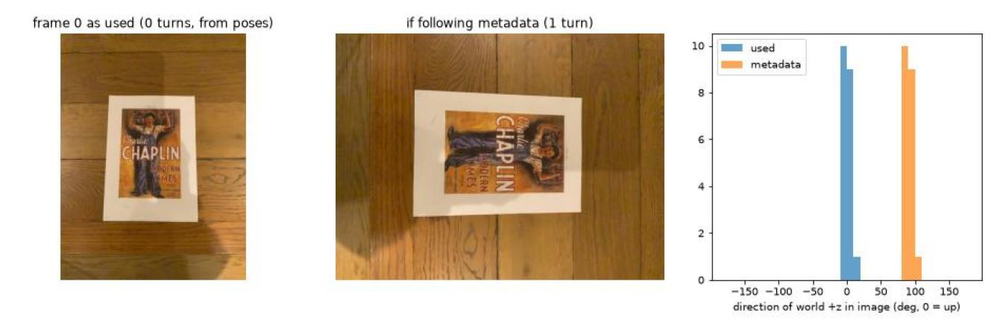

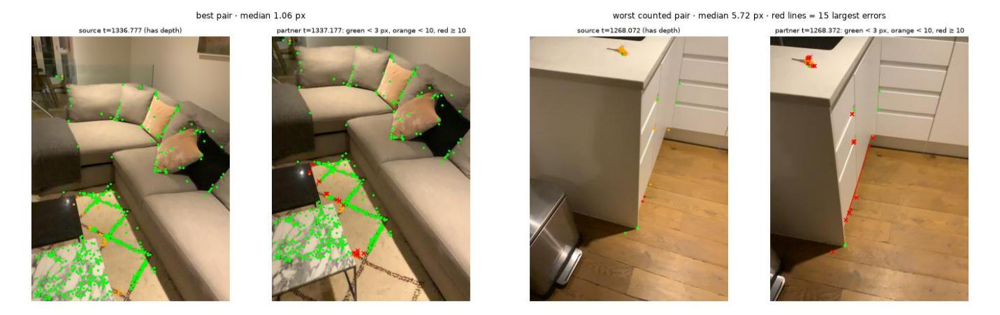

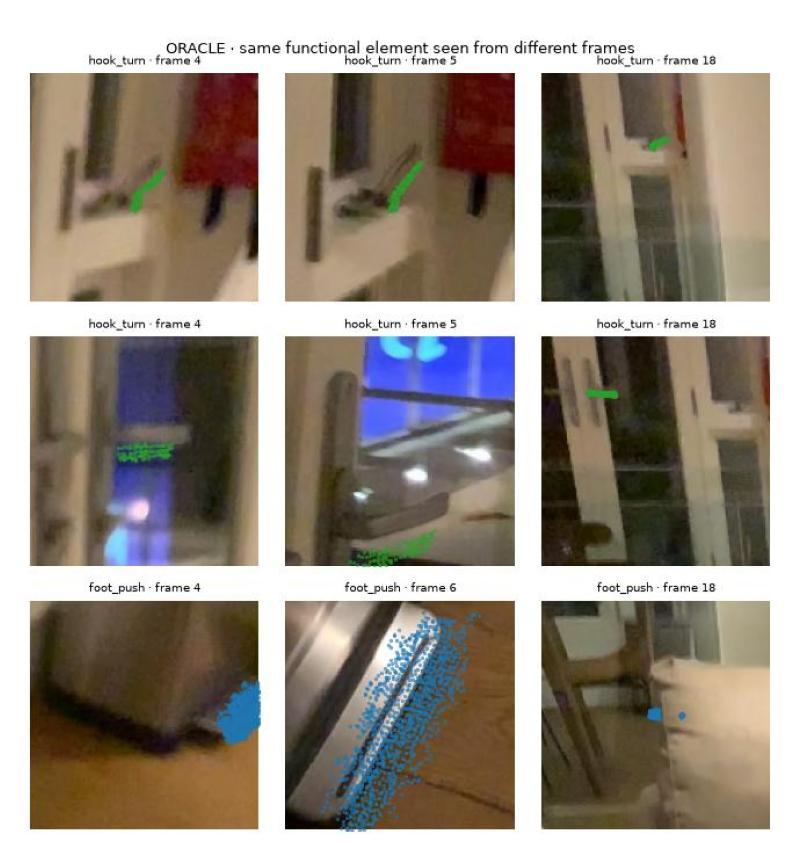

In [11]:
show_row([(E0 / "step2_orientation.jpg", "")], width=15)
show_row([(E0 / "step5_best_pair.jpg", ""), (E0 / "step5_worst_pair.jpg", "")], width=16)
crops = iio.imread(E0 / "step6b_multiview_crops.jpg")[:712]  # first three parts
show_row([(crops, "")], width=9)
plt.show()

**Findings**
- The ARKitScenes `sky_direction` metadata is wrong for hires frames, so rotation is derived from the poses.
- The largest errors are on thin or movable objects and depth edges (worst pair above: flowers, cabinet edge). Depth is rendered from the scan mesh, so these regions are unreliable for E1.
- Functional parts are small: a median of 106 scan points, i.e. a few cm.

## 6 · EPIC-KITCHENS + VISOR: one real kitchen video (P28_101)
> **This section:** what real interaction video looks like: 12 minutes of egocentric cooking with narrated actions, VISOR hand/object masks with contact links, and EPIC-Fields camera poses.  
> **Most promising:** contacts and narrations say *which object was touched, and when*. That is the "find my earlier interaction" query SceneFun3D cannot provide. EPIC-Fields poses place each interaction on a map, so it fits the same memory format as SceneFun3D.

Head-mounted camera, 1920×1080 · narrations from EPIC-KITCHENS-100 · VISOR manual masks on sparse frames · EPIC-Fields poses from structure-from-motion (no depth maps) · non-commercial licences.

In [12]:
EPIC = ROOT / "data" / "epic_visor"
visor = read_visor(EPIC / "P28_101" / "visor_annotations.json", EPIC / "P28_101" / "frames",
                   EPIC / "frame_mapping.json", "P28_101")
narrations, EPIC_FPS = read_narrations(EPIC / "EPIC_100_train.csv", "P28_101")
recon = read_epic_fields(EPIC / "P28_101" / "epic_fields.json")
kitchen = AlignedScene.from_recon(recon)  # rotated so that +z is up (from the head-mounted camera's image-down axis)
overview_table(visor, narrations, recon, EPIC_FPS)

,value
video,"P28_101 · 11 min 58 s · 50 fps · head-mounted,..."
narrated actions (EPIC-KITCHENS-100),120 (76 distinct)
VISOR annotated frames,201 in 34 short subsequences
VISOR masks,"1,049 masks, 32 hand / object classes"
frames with a hand–object contact,171
EPIC-Fields camera poses,"35,823 frames (99.8%)"
EPIC-Fields 3D points,"83,458 (SfM, arbitrary scale, no depth maps)"


### Walkthrough: every VISOR-annotated frame in time order

In [13]:
EPIC_VIDEO = ASSETS / "walkthrough_P28_101.mp4"
render_visor_walkthrough(visor, narrations, kitchen, EPIC_FPS, EPIC_VIDEO, fps=8)
Video(str(EPIC_VIDEO), embed=True, width=1100)

### 3D: EPIC-Fields points, camera path, and where each hand contact happened (hover a marker)

In [14]:
epic_3d_figure(kitchen, visor, EPIC_FPS)

### Object → earlier interactions

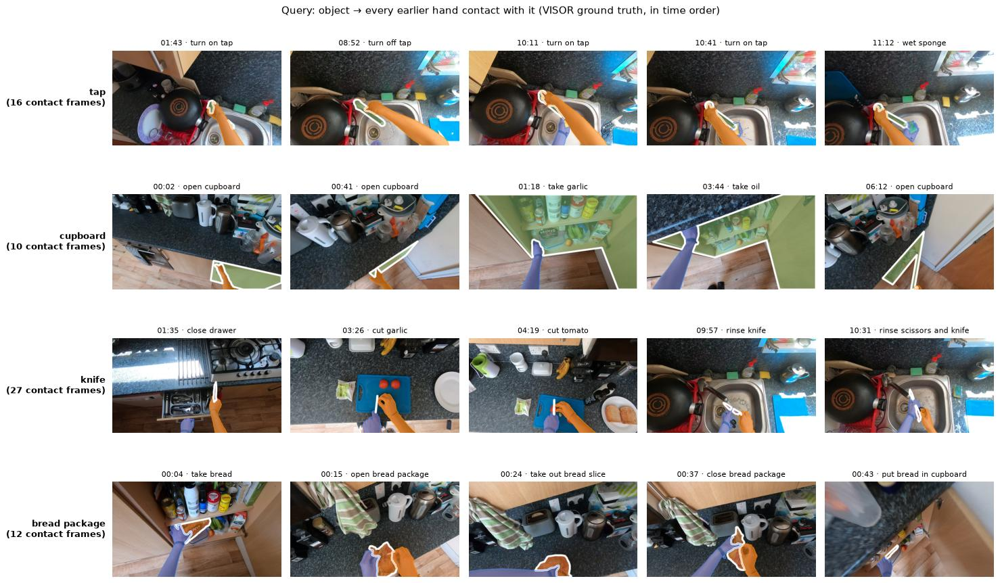

In [15]:
contact_examples_figure(visor, narrations, ["tap", "cupboard", "knife", "bread package"], EPIC_FPS)
plt.show()